# 05 - Model Training and Evaluation

Models: baseline, ridge regression, random forest, gradient boosting.

Metric agreed for this project: **MAE in q/ha, 6 weeks before harvest**. Over-forecasting and under-forecasting cost about the same per quintal, so plain MAE is a better fit than RMSE. I also report the tonnage-weighted error and the bias (net over/under forecast), because procurement works with volumes.

Extra metric: recall at 80% precision for shortfall seasons (yield more than 15% below the taluka's normal).

Targets to hit: at least 15% lower MAE than the baseline, test MAE within 5% of validation MAE, top drivers that make sense.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import json, joblib, time
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import precision_recall_curve
from sklearn.inspection import partial_dependence

d = pd.read_csv('../dataset/model_data.csv')
FEATS = json.load(open('../dataset/feature_list.json'))
CROPS = sorted(d.crop.unique()); DISTRICTS = sorted(d.district.unique())
CAT_IDX = [FEATS.index('crop_code'), FEATS.index('district_code')]

train = d[d.period == 'train']; valid = d[d.period == 'valid']; test = d[d.period == 'test']
print(len(train), len(valid), len(test))

81312 14784 14784


In [2]:
def score(rows, ratio_pred):
    # rows must be the lead-6 rows; ratio_pred is the predicted yield / baseline
    pred = np.asarray(ratio_pred) * rows.baseline.values
    y = rows.yield_q_ha.values
    err = pred - y
    a = rows.area_ha.values
    return pd.Series({
        'MAE_q_ha': np.abs(err).mean(),
        'tonnage_error_pct': 100 * (np.abs(err) * a).sum() / (y * a).sum(),
        'bias_pct': 100 * (err * a).sum() / (y * a).sum(),
    })

def make_models():
    return {
        'ridge': make_pipeline(SimpleImputer(strategy='median'), StandardScaler(), Ridge(alpha=10)),
        'random_forest': RandomForestRegressor(n_estimators=60, max_depth=12, min_samples_leaf=50, max_samples=0.3,
                                               max_features=0.5, n_jobs=1, random_state=0),
        'gradient_boosting': HistGradientBoostingRegressor(loss='absolute_error', learning_rate=0.08, max_iter=200, max_depth=6,
                                                           min_samples_leaf=100, categorical_features=CAT_IDX, random_state=0),
    }

def fit(model, rows):
    # weight by baseline so the loss is in q/ha, the same unit as the metric
    if hasattr(model, 'steps'):
        model.fit(rows[FEATS], rows.y_ratio, ridge__sample_weight=rows.baseline)
    else:
        model.fit(rows[FEATS], rows.y_ratio, sample_weight=rows.baseline)
    return model

# ridge cannot use crop/district as numbers: give it dummies by adding them to a copy of the features
def ridge_view(rows):
    x = rows[FEATS].drop(columns=['crop_code', 'district_code']).copy()
    for c in CROPS: x['crop_' + c] = (rows.crop == c).astype(int)
    for k in DISTRICTS: x['dist_' + k] = (rows.district == k).astype(int)
    return x

def fit_predict(name, model, tr, te):
    if name == 'ridge':
        model.fit(ridge_view(tr), tr.y_ratio, ridge__sample_weight=tr.baseline)
        return model, model.predict(ridge_view(te))
    fit(model, tr)
    return model, model.predict(te[FEATS])

## Cross-validation (expanding window by year)

In [3]:
folds = [2019, 2020, 2021]
rows = []
for name in ['baseline', 'ridge', 'random_forest', 'gradient_boosting']:
    for yr in folds:
        tr = d[d.season_year < yr]
        va = d[(d.season_year == yr) & d.lead6]
        if name == 'baseline':
            p = np.ones(len(va))
        else:
            _, p = fit_predict(name, make_models()[name], tr, va)
        r = score(va, p); r['model'] = name; r['fold'] = yr
        rows.append(r)
cv = pd.DataFrame(rows)
summary = cv.groupby('model')[['MAE_q_ha', 'tonnage_error_pct', 'bias_pct']].mean().loc[['baseline', 'ridge', 'random_forest', 'gradient_boosting']]
summary['MAE_gain_vs_baseline_pct'] = 100 * (1 - summary.MAE_q_ha / summary.loc['baseline', 'MAE_q_ha'])
summary.round(3)

                   MAE_q_ha  tonnage_error_pct  bias_pct  MAE_gain_vs_baseline_pct
model                                                                             
baseline              1.519             10.747    -4.642                     0.000
ridge                 1.330              9.448    -1.205                    12.468
random_forest         1.143              8.103    -1.060                    24.802
gradient_boosting     1.156              8.173    -1.032                    23.919


## Tuning the gradient boosting model

Small search (4 settings, one CPU), scored with the same 3 folds.

In [4]:
grid = [
    dict(learning_rate=0.08, max_iter=200, max_depth=6, min_samples_leaf=100, l2_regularization=0.0),
    dict(learning_rate=0.08, max_iter=200, max_depth=4, min_samples_leaf=100, l2_regularization=1.0),
    dict(learning_rate=0.08, max_iter=200, max_depth=6, min_samples_leaf=200, l2_regularization=5.0),
    dict(learning_rate=0.1, max_iter=150, max_depth=5, min_samples_leaf=50, l2_regularization=1.0),
]
res = []
for i, params in enumerate(grid):
    maes = []
    for yr in folds:
        tr = d[d.season_year < yr]; va = d[(d.season_year == yr) & d.lead6]
        m = HistGradientBoostingRegressor(loss='absolute_error', categorical_features=CAT_IDX, random_state=0, **params)
        fit(m, tr)
        maes.append(score(va, m.predict(va[FEATS])).MAE_q_ha)
    res.append(dict(config=i, mae=np.mean(maes), **params))
tuning = pd.DataFrame(res).sort_values('mae')
best_params = grid[int(tuning.iloc[0].config)]
print(tuning.round(4).to_string(index=False))
print('best:', best_params)

 config    mae  learning_rate  max_iter  max_depth  min_samples_leaf  l2_regularization
      3 1.1498           0.10       150          5                50                1.0
      1 1.1540           0.08       200          4               100                1.0
      0 1.1560           0.08       200          6               100                0.0
      2 1.1600           0.08       200          6               200                5.0
best: {'learning_rate': 0.1, 'max_iter': 150, 'max_depth': 5, 'min_samples_leaf': 50, 'l2_regularization': 1.0}


## Validation (2022-2023) and test (2024-2025)

Models for validation are trained on 2011-2021. For the test period the final model is trained again on 2011-2023, which is what would be done in production. The test years were not used for any choice.

In [5]:
va = valid[valid.lead6]; te = test[test.lead6]
results = {}
preds_val = {'baseline': np.ones(len(va))}
for name in ['ridge', 'random_forest']:
    _, preds_val[name] = fit_predict(name, make_models()[name], train, va)

best = lambda: HistGradientBoostingRegressor(loss='absolute_error', categorical_features=CAT_IDX, random_state=0, **best_params)
gb_val = fit(best(), train)
preds_val['gb_tuned'] = gb_val.predict(va[FEATS])

val_table = pd.DataFrame({k: score(va, v) for k, v in preds_val.items()}).T
val_table['MAE_gain_vs_baseline_pct'] = 100 * (1 - val_table.MAE_q_ha / val_table.loc['baseline', 'MAE_q_ha'])
print('VALIDATION'); print(val_table.round(3).to_string())

trainval = d[d.period != 'test']
gb_final = fit(best(), trainval)
pred_test = gb_final.predict(te[FEATS])
test_table = pd.DataFrame({'baseline': score(te, np.ones(len(te))), 'gb_tuned': score(te, pred_test)}).T
test_table['MAE_gain_vs_baseline_pct'] = 100 * (1 - test_table.MAE_q_ha / test_table.loc['baseline', 'MAE_q_ha'])
print(); print('TEST'); print(test_table.round(3).to_string())

mae_val, mae_test = val_table.loc['gb_tuned', 'MAE_q_ha'], test_table.loc['gb_tuned', 'MAE_q_ha']
print()
print('success check 1 - gain over baseline: val %.1f%%, test %.1f%% (need >= 15)' % (val_table.loc['gb_tuned', 'MAE_gain_vs_baseline_pct'], test_table.loc['gb_tuned', 'MAE_gain_vs_baseline_pct']))
print('success check 2 - test MAE vs val MAE: %.3f vs %.3f -> %.1f%% difference (need <= 5)' % (mae_test, mae_val, 100 * (mae_test / mae_val - 1)))

VALIDATION
               MAE_q_ha  tonnage_error_pct  bias_pct  MAE_gain_vs_baseline_pct
baseline          1.594             10.723     0.612                     0.000
ridge             1.338              9.134     0.028                    16.032
random_forest     1.261              8.551     0.786                    20.887
gb_tuned          1.270              8.706     0.454                    20.335

TEST
          MAE_q_ha  tonnage_error_pct  bias_pct  MAE_gain_vs_baseline_pct
baseline     1.557             10.550    -2.959                     0.000
gb_tuned     1.211              8.299    -2.125                    22.185

success check 1 - gain over baseline: val 20.3%, test 22.2% (need >= 15)
success check 2 - test MAE vs val MAE: 1.211 vs 1.270 -> -4.6% difference (need <= 5)


**Result.** Tuned gradient boosting beats the baseline by 20.3% on validation and 22.2% on test (target 15%). Test MAE (1.211) is 4.6% *lower* than validation MAE (1.270), so it is inside the 5% band, but only just in absolute terms; the test years happened to be a little easier. The gain is stable year by year (17.5% to 26.7%).

Two things to keep in mind. Random forest was marginally better than boosting in cross-validation (1.143 vs 1.156 before tuning) and on validation (1.261 vs 1.270); I tuned boosting as planned, but the two are practically tied. And ridge already gets 16% on validation, so a simple linear model captures most of the gain.

 year  baseline  model  gain_pct
 2022     1.611  1.295    19.630
 2023     1.576  1.244    21.056
 2024     1.531  1.262    17.544
 2025     1.583  1.160    26.675
                      baseline  model
weeks_before_harvest                 
4                        1.594  1.255
6                        1.594  1.270
8                        1.594  1.286
10                       1.594  1.298
12                       1.594  1.316
14                       1.594  1.308
16                       1.644  1.402


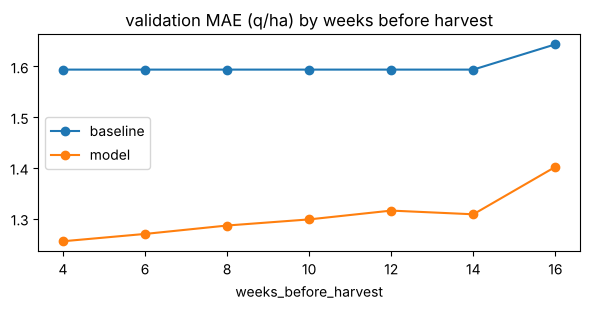

In [6]:
# error by year and by weeks before harvest (how early can we forecast?)
yr_tab = []
for yr in [2022, 2023, 2024, 2025]:
    g = d[d.lead6 & (d.season_year == yr)]
    m = gb_val if yr <= 2023 else gb_final
    yr_tab.append(dict(year=yr, baseline=score(g, np.ones(len(g))).MAE_q_ha, model=score(g, m.predict(g[FEATS])).MAE_q_ha))
yr_tab = pd.DataFrame(yr_tab)
yr_tab['gain_pct'] = 100 * (1 - yr_tab.model / yr_tab.baseline)
print(yr_tab.round(3).to_string(index=False))

lead_rows = []
for lead in range(4, 17, 2):
    g = valid[valid.weeks_to_harvest == lead]
    lead_rows.append(dict(weeks_before_harvest=lead, baseline=score(g, np.ones(len(g))).MAE_q_ha, model=score(g, gb_val.predict(g[FEATS])).MAE_q_ha))
lead_df = pd.DataFrame(lead_rows).set_index('weeks_before_harvest')
lead_df.plot(marker='o', figsize=(6, 3.2), title='validation MAE (q/ha) by weeks before harvest')
plt.tight_layout(); plt.savefig('../reports/figures/05_lead_time.png', dpi=120)
lead_df.round(3)

## Shortfall alerts (recall at 80% precision)

A shortfall season = yield below 85% of the taluka's baseline. The threshold on the predicted ratio is picked on validation and then applied unchanged to test. The comparison rule is a simple one: flag talukas whose rain so far is lowest compared with normal.

In [7]:
def pick_threshold(y_short, s, min_precision=0.8):
    # lowest threshold that still keeps precision above the target; steps down if 80% is not reachable
    for target in (min_precision, 0.7, 0.6, 0.5):
        p, r, t = precision_recall_curve(y_short, s)
        ok = np.where(p[:-1] >= target)[0]
        if len(ok):
            return t[ok[np.argmax(r[ok])]], target
    return t[0], 0

va_short = (va.y_ratio < 0.85).values
te_short = (te.y_ratio < 0.85).values
print('shortfall share: valid %.1f%%, test %.1f%%' % (100 * va_short.mean(), 100 * te_short.mean()))

def alert_stats(y_short, s, thr):
    flag = s >= thr
    return dict(precision=(y_short & flag).sum() / max(flag.sum(), 1), recall=(y_short & flag).sum() / max(y_short.sum(), 1), flagged=int(flag.sum()))

out = {}
for name, s_val, s_test in [('rain rule', -va.cum_rain_ratio.values, -te.cum_rain_ratio.values),
                            ('model', -preds_val['gb_tuned'], -pred_test)]:
    thr, used_target = pick_threshold(va_short, s_val)
    out[name] = {'valid': alert_stats(va_short, s_val, thr), 'test': alert_stats(te_short, s_test, thr)}
    out[name]['precision_target_used'] = used_target
    if name == 'model':
        MODEL_THR = -thr          # flag a taluka when predicted ratio <= MODEL_THR
for name, v in out.items():
    print(name, '(precision target %.1f)' % v['precision_target_used'])
    print(pd.DataFrame({k: v[k] for k in ('valid', 'test')}).T.round(3).to_string())

shortfall share: valid 12.1%, test 8.5%
rain rule (precision target 0.6)
       precision  recall  flagged
valid      0.667   0.020      3.0
test       0.250   0.028      8.0
model (precision target 0.8)
       precision  recall  flagged
valid        0.8   0.039      5.0
test         1.0   0.028      2.0


**Result: the shortfall alert is weak.** About 12% of validation seasons are shortfalls. At the chosen threshold the model flags only 5 of 840 rows on validation (recall 4%, precision 80%) and 2 on test (recall 3%). The simple rain rule is no better. So the model is good at predicting the *size* of the yield (MAE) but not at singling out the bad seasons 6 weeks ahead. I would not use it as an alarm; use the volume forecast instead.

## Fairness and stability

Does the model work equally well for every district, crop and farm size group? And is it biased in one direction anywhere? If a district is consistently over- or under-forecast, procurement would be mis-planned there.

In [8]:
va = va.copy(); te = te.copy()
va['pred'] = preds_val['gb_tuned'] * va.baseline; te['pred'] = pred_test * te.baseline
for x in (va, te):
    x['abs_err'] = (x.pred - x.yield_q_ha).abs()
    x['signed_pct'] = 100 * (x.pred - x.yield_q_ha) / x.yield_q_ha
    x['size_group'] = pd.qcut(x.area_ha, 3, labels=['small', 'medium', 'large'])

def by_group(x, col):
    return x.groupby(col).agg(MAE=('abs_err', 'mean'), bias_pct=('signed_pct', 'mean')).round(3)

print('VALIDATION by district'); print(by_group(va, 'district'))
print('\nVALIDATION by crop'); print(by_group(va, 'crop'))
print('\nVALIDATION by farm size (area) group'); print(by_group(va, 'size_group'))
print('\nTEST by district'); print(by_group(te, 'district'))

VALIDATION by district
              MAE  bias_pct
district                   
Akola       1.193     2.729
Amravati    1.209     1.583
Chandrapur  1.293    -0.838
Nagpur      1.298     0.412
Wardha      1.286     0.053
Yavatmal    1.339     3.038

VALIDATION by crop
           MAE  bias_pct
crop                    
cotton   0.564     1.890
gram     0.951     0.986
soybean  1.081    -0.130
tur      0.764     1.806
wheat    2.987     1.263

VALIDATION by farm size (area) group
              MAE  bias_pct
size_group                 
small       1.366     1.401
medium      1.266     0.911
large       1.178     1.178

TEST by district
              MAE  bias_pct
district                   
Akola       1.071    -1.369
Amravati    1.368    -2.602
Chandrapur  1.179     2.104
Nagpur      1.239    -1.551
Wardha      1.282    -1.659
Yavatmal    1.129     0.280


In [9]:
# bias fix, if needed: per-district offset on the predicted ratio, learned only from out-of-fold predictions of the CV years
oof = []
for yr in folds:
    tr = d[d.season_year < yr]; vv = d[(d.season_year == yr) & d.lead6].copy()
    m = fit(best(), tr)
    vv['res'] = vv.y_ratio - m.predict(vv[FEATS])
    oof.append(vv)
oof = pd.concat(oof)
offsets = oof.groupby('district').res.median()
print('district offsets (ratio units):'); print(offsets.round(4).to_string())

cal_val = preds_val['gb_tuned'] + va.district.map(offsets).values
cal_test = pred_test + te.district.map(offsets).values
print('validation, before and after offsets'); print(pd.DataFrame({'before': score(va, preds_val['gb_tuned']), 'after': score(va, cal_val)}).T.round(3))
bias_after = (100 * (cal_val * va.baseline.values - va.yield_q_ha.values) / va.yield_q_ha.values)
print('worst district bias before: %.2f%%  after: %.2f%%' % (va.groupby('district').signed_pct.mean().abs().max(), pd.Series(bias_after).groupby(va.district.values).mean().abs().max()))

district offsets (ratio units):
district
Akola         0.0345
Amravati     -0.0163
Chandrapur    0.0250
Nagpur        0.0046
Wardha        0.0057
Yavatmal      0.0231
validation, before and after offsets
        MAE_q_ha  tonnage_error_pct  bias_pct
before     1.270              8.706     0.454
after      1.297              8.912     1.632
worst district bias before: 3.04%  after: 6.27%


In [10]:
# decide: only use the offsets if they help on validation
use_offsets = score(va, cal_val).MAE_q_ha < score(va, preds_val['gb_tuned']).MAE_q_ha
print('use district offsets:', use_offsets)
print('test MAE without offsets %.3f, with offsets %.3f' % (score(te, pred_test).MAE_q_ha, score(te, cal_test).MAE_q_ha))

use district offsets: False
test MAE without offsets 1.211, with offsets 1.235


District bias is small (worst district about 3% on validation, about 2.6% on test, and the direction changes between the two periods), so there is no consistent unfairness to fix. The per-district offsets made validation MAE and bias worse, so **they are not applied**. Errors are similar across farm-size groups (MAE 1.37 small, 1.27 medium, 1.18 large on validation). By crop, wheat has the largest error in q/ha (2.99) because its yield level is about 3x the others; in percent terms the crops are closer.

## How much do the weather, soil and price features add?

Same tuned model, trained with feature groups added one at a time (validation, 6 weeks before harvest). This shows how much of the gain over the baseline is just history and how much is real weather information.

In [11]:
groups = {
    'history only (lags, rolling, taluka effect, crop, district)': ['yield_lag1', 'yield_lag2', 'yield_lag3', 'yield_roll3_mean', 'yield_roll3_std', 'yield_trend', 'taluka_effect', 'weeks_to_harvest', 'crop_code', 'district_code'],
    '+ rain and temperature': ['rain_roll4', 'rain_roll8', 'cum_rain_ratio', 'rain_before_sowing', 'dry_run_max', 'rain_missing_share', 'tmax_roll4', 'cum_heat'],
    '+ soil and irrigation': ['soil_N', 'soil_OC', 'soil_pH', 'n_p_ratio', 'irrigated_share'],
    '+ price': ['price_mom', 'price_yoy'],
}
used, rows_ = [], []
va6 = valid[valid.lead6]
for name, cols in groups.items():
    used = used + cols
    feats = [f for f in FEATS if f in used]
    m = HistGradientBoostingRegressor(loss='absolute_error', categorical_features=[feats.index('crop_code'), feats.index('district_code')], random_state=0, **best_params)
    m.fit(train[feats], train.y_ratio, sample_weight=train.baseline)
    mae_ = score(va6, m.predict(va6[feats])).MAE_q_ha
    rows_.append(dict(feature_set=name, n_features=len(feats), valid_MAE=mae_, gain_vs_baseline_pct=100 * (1 - mae_ / score(va6, np.ones(len(va6))).MAE_q_ha)))
ablation = pd.DataFrame(rows_)
print(ablation.round(3).to_string(index=False))

                                                feature_set  n_features  valid_MAE  gain_vs_baseline_pct
history only (lags, rolling, taluka effect, crop, district)          10      1.599                -0.316
                                     + rain and temperature          18      1.253                21.383
                                      + soil and irrigation          23      1.261                20.879
                                                    + price          25      1.270                20.335


## Explaining the model

Shapley values show how much each feature moved a prediction away from the average one. The `shap` package was not available in my environment, so I wrote a small sampling version (random feature orders, replacing features one at a time with values from a background row). It is slower and a bit noisier than TreeSHAP but gives the same kind of numbers. Values are in "percentage points of normal yield".

Partial dependence plots come from scikit-learn.

rain_before_sowing    7.28
crop_code             3.99
yield_lag2            2.34
yield_roll3_std       1.99
yield_roll3_mean      1.91
cum_rain_ratio        1.68
soil_N                1.05
yield_lag1            0.92
yield_lag3            0.79
taluka_effect         0.75
dtype: float64


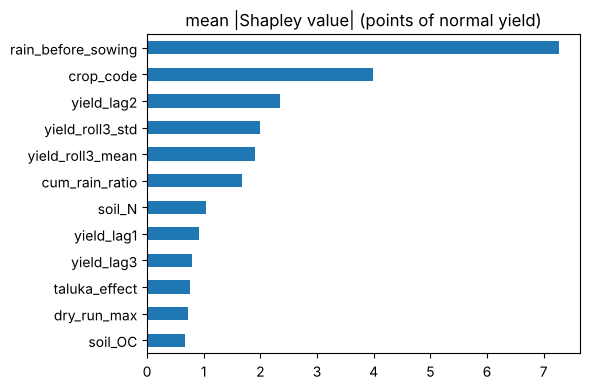

In [12]:
def shapley(predict, X, background, n_perm=15, seed=0):
    rng = np.random.default_rng(seed)
    n, f = X.shape
    phi = np.zeros((n, f))
    for _ in range(n_perm):
        order = rng.permutation(f)
        cur = background[rng.integers(0, len(background), n)].copy()
        prev = predict(cur)
        for j in order:
            cur[:, j] = X[:, j]
            new = predict(cur)
            phi[:, j] += new - prev
            prev = new
    return phi / n_perm

rs = np.random.RandomState(1)
sample = va.sample(min(800, len(va)), random_state=1)
bg = train[train.lead6].sample(100, random_state=1)[FEATS].values
phi = shapley(gb_val.predict, sample[FEATS].values, bg) * 100
imp = pd.Series(np.abs(phi).mean(axis=0), index=FEATS).sort_values(ascending=False)
print(imp.head(10).round(2))

imp.head(12)[::-1].plot.barh(figsize=(6, 4), title='mean |Shapley value| (points of normal yield)')
plt.tight_layout(); plt.savefig('../reports/figures/05_importance.png', dpi=120)

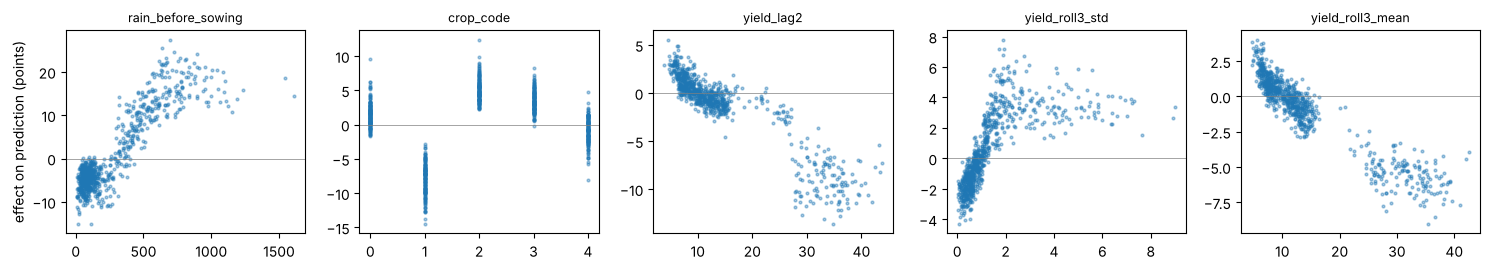

In [13]:
top5 = list(imp.index[:5])
fig, ax = plt.subplots(1, 5, figsize=(15, 2.8))
for a, f in zip(ax, top5):
    a.scatter(sample[f], phi[:, FEATS.index(f)], s=4, alpha=0.4)
    a.set_title(f, fontsize=9); a.axhline(0, color='grey', lw=0.5)
ax[0].set_ylabel('effect on prediction (points)')
plt.tight_layout(); plt.savefig('../reports/figures/05_shap_dependence.png', dpi=120)

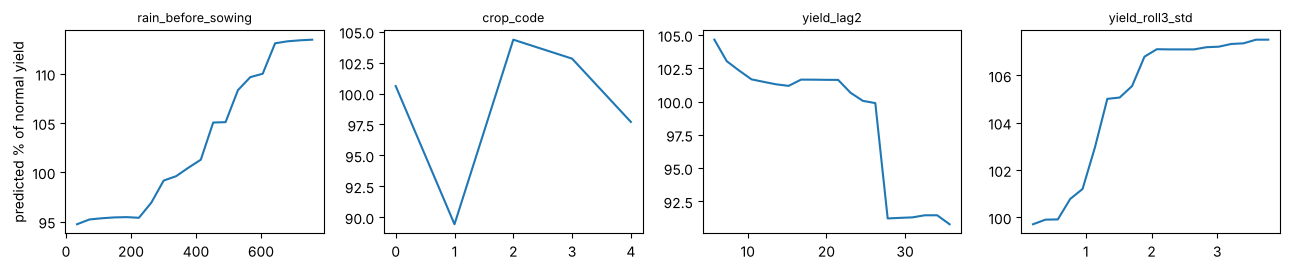

In [14]:
pdp_rows = valid.sample(2500, random_state=2)[FEATS].astype(float)    # all lead times, so the curves are smoother
fig, ax = plt.subplots(1, 4, figsize=(13, 2.8))
for a, f in zip(ax, top5[:4]):
    pd_ = partial_dependence(gb_val, pdp_rows, [FEATS.index(f)], grid_resolution=20, kind='average', method='brute')
    a.plot(pd_['grid_values'][0], 100 * pd_['average'][0])
    a.set_title(f, fontsize=9)
ax[0].set_ylabel('predicted % of normal yield')
plt.tight_layout(); plt.savefig('../reports/figures/05_pdp.png', dpi=120)

**Top drivers (mean absolute Shapley value, points of normal yield):** rain_before_sowing 7.3, crop 4.0, yield_lag2 2.3, yield_roll3_std 2.0, yield_roll3_mean 1.9; then cum_rain_ratio 1.7 and soil_N 1.1.

Do they make business sense? Partly.
- Crop, and the taluka's recent yield level and volatility: yes. They set the scale of a normal season and how much it swings.
- Rain: yes, the ablation above says rain and temperature features carry essentially the whole gain (history alone gives -0.3%; adding weather gives 21.4%).
- Soil, irrigation and price: they add nothing in the ablation (slightly worse). `soil_N` in the top 10 is probably noise.
- `rain_before_sowing` is #1 but I would not read it as pure agronomy. It is high for rabi crops (sown after the monsoon) and low for kharif crops, so it also separates the two seasons. Rain so far compared with normal (`cum_rain_ratio`), the feature I expected to lead, is only 6th.

So the top five are explainable but not all of them are clean. A version 2 should drop price and soil features and replace `rain_before_sowing` with a rabi-only moisture feature.

## One wrong prediction in detail

Take the largest relative miss in the test period at 6 weeks before harvest.

In [15]:
te['rel_err'] = (te.pred - te.yield_q_ha) / te.yield_q_ha
bad = te.loc[te.rel_err.abs().idxmax()]
print(bad[['taluka', 'crop', 'season_year', 'season_week']].to_string())
print('baseline (3-yr mean): %.2f q/ha | model: %.2f q/ha | actual: %.2f q/ha | model error %.0f%%' % (bad.baseline, bad.pred, bad.yield_q_ha, 100 * bad.rel_err))
print('area: %.0f ha -> volume miss about %.0f quintals' % (bad.area_ha, abs(bad.pred - bad.yield_q_ha) * bad.area_ha))

# what drove this prediction (Shapley for this one row)
row = te.loc[[bad.name]][FEATS].values
phi1 = shapley(gb_final.predict, row, bg, n_perm=60)[0] * 100
local = pd.Series(phi1, index=FEATS).sort_values(key=np.abs, ascending=False).head(6)
print('\nbiggest pushes on this prediction (points of normal yield):'); print(local.round(1).to_string())
print('\nfeature values: ', {k: round(float(bad[k]), 2) for k in ['cum_rain_ratio', 'dry_run_max', 'cum_heat', 'rain_missing_share', 'yield_trend', 'irrigated_share']})

taluka         Chandrapur-T12
crop                  soybean
season_year              2024
season_week                12
baseline (3-yr mean): 13.25 q/ha | model: 15.14 q/ha | actual: 8.62 q/ha | model error 76%
area: 8440 ha -> volume miss about 54994 quintals

biggest pushes on this prediction (points of normal yield):
yield_roll3_std       5.8
crop_code             5.7
irrigated_share       2.9
yield_roll3_mean     -2.8
rain_before_sowing   -1.9
rain_roll8            1.7

feature values:  {'cum_rain_ratio': 1.29, 'dry_run_max': 1.0, 'cum_heat': 0.0, 'rain_missing_share': 0.08, 'yield_trend': 1.14, 'irrigated_share': 0.42}


In [16]:
# what happened AFTER the forecast date (the model could not see this)
cl = pd.read_csv('../dataset/cleaned_dataset.csv', usecols=['taluka', 'crop', 'season_year', 'district', 'season_week', 'rain_mm', 'tmax_c', 'rain_was_missing'])
s = cl[(cl.taluka == bad.taluka) & (cl.crop == bad.crop) & (cl.season_year == bad.season_year)].sort_values('season_week')
h = {'soybean': 18, 'cotton': 30, 'tur': 28, 'wheat': 17, 'gram': 15}[bad.crop]
after = s[(s.season_week > bad.season_week) & (s.season_week <= h - 3)]
before = s[s.season_week <= bad.season_week]
norm = cl[(cl.district == bad.district) & (cl.crop == bad.crop) & (cl.season_year <= 2021)]
norm_after = norm[(norm.season_week > bad.season_week) & (norm.season_week <= h - 3)].groupby(['taluka', 'season_year']).rain_mm.sum().mean()
print('rain in weeks before forecast: %.0f mm (missing readings: %d weeks)' % (before.rain_mm.sum(), before.rain_was_missing.sum()))
print('rain between forecast and harvest-3: %.0f mm vs normal %.0f mm' % (after.rain_mm.sum(), norm_after))
print('hot weeks (>36C) after forecast: %d' % (after.tmax_c > 36).sum())
run = best_run = 0
for v in (after.rain_mm < 8):
    run = run + 1 if v else 0
    best_run = max(best_run, run)
print('longest dry run after forecast: %d weeks' % best_run)

rain in weeks before forecast: 992 mm (missing readings: 1 weeks)
rain between forecast and harvest-3: 371 mm vs normal 88 mm
hot weeks (>36C) after forecast: 0
longest dry run after forecast: 0 weeks


**What happened.** Chandrapur-T12, soybean, 2024, forecast at season week 12. Baseline 13.25 q/ha, model 15.14, actual 8.62. The model was 76% too high, about 55,000 quintals on 8,440 ha.

**What the model saw.** Rain so far 29% above normal, no dry spell, no heat, one missing rain week, a rising yield trend. Nothing in that looked like trouble, and the biggest pushes were upward (yield volatility and crop identity).

**What it could not see.** Between the forecast date and harvest minus 3 weeks the taluka got 371 mm of rain against a normal of 88 mm, on top of 992 mm already fallen. In this synthetic data, season rain far above crop need (about 1.9x) cuts yield through waterlogging, and this season was around 3x. That late rain is weather after the forecast date, so no forecast made at this point could know it.

**What it tells us.**
1. Most of this miss is unavoidable at 6 weeks lead. The fix is process: refresh the forecast every week until 4 weeks before harvest and treat a forecast as a range.
2. I did not check how the model responds to extreme rain already fallen (the cum_rain_ratio partial dependence plot above is where to look), and the training data has few seasons that wet. Extreme-rain cases should be reviewed by hand.
3. Missing rain readings are not the cause here (1 missing week).

## Procurement priorities (season 2025, forecast 6 weeks before harvest)

In [17]:
te['pred_ratio_raw'] = pred_test
te['pred_final'] = (cal_test if use_offsets else pred_test) * te.baseline
latest = te[te.season_year == 2025].copy()
latest['expected_tonnes'] = latest.pred_final * latest.area_ha / 10
latest['normal_tonnes'] = latest.baseline * latest.area_ha / 10
latest['at_risk'] = (latest.pred_ratio_raw <= MODEL_THR).astype(int)

tab = latest.groupby(['district', 'crop']).agg(expected_tonnes=('expected_tonnes', 'sum'), normal_tonnes=('normal_tonnes', 'sum'),
                                              talukas_at_risk_pct=('at_risk', 'mean'), price_yoy_pct=('price_yoy', 'mean')).reset_index()
tab['talukas_at_risk_pct'] *= 100
tab['price_yoy_pct'] *= 100
tab['volume_change_pct'] = 100 * (tab.expected_tonnes / tab.normal_tonnes - 1)

def action(r):
    if r.volume_change_pct <= -6 or r.talukas_at_risk_pct >= 30:
        return '1 secure supply early'
    if r.volume_change_pct >= 6:
        return '3 expect surplus, buy opportunistically'
    return '2 normal plan'
tab['action'] = tab.apply(action, axis=1)
tab = tab.sort_values(['action', 'volume_change_pct'])
tab.round(1).to_csv('../reports/procurement_priorities_2025.csv', index=False)
print(tab.round(1).to_string(index=False))

  district    crop  expected_tonnes  normal_tonnes  talukas_at_risk_pct  price_yoy_pct  volume_change_pct                action
     Akola   wheat         148708.9       159639.9                  0.0           -5.3               -6.8 1 secure supply early
     Akola    gram          59316.0        63462.5                  0.0          -13.2               -6.5 1 secure supply early
    Nagpur   wheat         315619.3       337483.4                  0.0           -7.3               -6.5 1 secure supply early
  Yavatmal   wheat         228102.9       242135.0                 14.3           -4.3               -5.8         2 normal plan
Chandrapur   wheat         348335.2       365041.5                  0.0           -7.4               -4.6         2 normal plan
  Yavatmal  cotton          68030.2        70577.7                  0.0           -3.1               -3.6         2 normal plan
    Nagpur    gram         108755.0       112635.3                  0.0          -14.6               -3.

**Reading the table (2025 season, forecast 6 weeks before harvest).**

- **Secure supply early:** Akola wheat (-6.8% vs normal volume), Akola gram (-6.5%), Nagpur wheat (-6.5%). Yavatmal wheat is just under the line (-5.8%, with 14% of its talukas flagged).
- **Surplus:** no district-crop reaches +6%. The largest is Amravati cotton (+5.6%) and Chandrapur soybean (+5.3%).
- **Price view:** soybean and tur prices are 15-18% above last year with normal volumes, so buying will cost more and forward contracts early are worth considering. Gram prices are 13-15% below last year with normal volume, which is a chance to buy more.
- **Everything else:** normal plan.

Be careful with the size of these differences. They are mostly under 7%, and I did not measure the error at district-crop level, only at taluka level (about 8% tonnage error). Treat the three "secure supply" rows as the ones to look at first, not as sure shortfalls. The model's shortfall alert fired in almost no talukas, so these rankings rest on the volume forecast only.

## Save the model

In [18]:
bundle = {
    'model': gb_final,
    'features': FEATS,
    'crops': CROPS,
    'districts': DISTRICTS,
    'district_offsets': offsets.to_dict() if use_offsets else {},
    'shortfall_threshold': float(MODEL_THR),
    'best_params': best_params,
    'defaults': train[train.lead6][FEATS].median().to_dict(),     # used by app.py for inputs the user does not give
    'trained_on': '2011-2023, forecast origin 4+ weeks before harvest',
}
joblib.dump(bundle, '../models/best_model.pkl')

metrics = {
    'validation': val_table.round(4).to_dict('index'),
    'test': test_table.round(4).to_dict('index'),
    'cv': summary.round(4).to_dict('index'),
    'shortfall': {k: v for k, v in out.items()},
    'top_features': list(imp.head(8).index),
    'use_offsets': bool(use_offsets),
}
json.dump(metrics, open('../reports/metrics.json', 'w'), indent=1, default=float)
va.to_csv('../reports/valid_predictions.csv', index=False)
te.to_csv('../reports/test_predictions.csv', index=False)

# make sure the saved file loads and predicts
b = joblib.load('../models/best_model.pkl')
print(b['model'].predict(te[b['features']].head(3)), te.y_ratio.head(3).values)

[1.0088359  0.91074509 0.96331231] [1.04738826 0.88479113 1.16871687]
